In [28]:
# 1. Importando o pandas e carregando o dataset processado
import pandas as pd

df = pd.read_csv('../data/processed/dataset_preprocessed.csv')

# 2. Definindo o Alvo (y): o tempo real de entrega em minutos
y = df['actual_delivery_time_minutes']

# 3. Definindo as Variáveis (X): tirando o alvo e colunas que causam vazamento de dados (data leakage)
colunas_para_remover = [
    'actual_delivery_time_minutes', 
    'estimated_delivery_time_minutes', 
    'late_delivery'
]

X = df.select_dtypes(include=['number']).drop(columns=colunas_para_remover, errors='ignore')

print(f"Total de características usadas agora: {X.shape[1]}")

Total de características usadas agora: 30


In [29]:
# 4. Dividindo os dados em Treino (80%) e Teste (20%)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Linhas para o modelo estudar (treino): {X_train.shape[0]}")
print(f"Linhas para a prova final (teste): {X_test.shape[0]}")

Linhas para o modelo estudar (treino): 39305
Linhas para a prova final (teste): 9827


In [30]:
# 5. Importando, treinando e avaliando o modelo de Regressão Linear
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Inicializando o modelo de Regressão Linear
model_reg = LinearRegression()

# O modelo aprende os padrões relacionando as características com o tempo de entrega
model_reg.fit(X_train, y_train)

# 6. Gerando previsões para a prova final (dados de teste)
y_pred = model_reg.predict(X_test)

# Calculando as métricas de erro e qualidade
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Erro Médio Absoluto (MAE): {mae:.2f} minutos")
print(f"Coeficiente de Determinação (R²): {r2:.2f}")

Erro Médio Absoluto (MAE): 0.02 minutos
Coeficiente de Determinação (R²): 0.94


In [31]:
# 7. Descobrindo o peso de cada fator no tempo de entrega
import pandas as pd

coeficientes = pd.DataFrame({
    'Variavel': X.columns,
    'Peso_Minutos': model_reg.coef_
}).sort_values(by='Peso_Minutos', ascending=False)

print("Top fatores que mais influenciam o tempo de entrega:")
print(coeficientes.head(10))

Top fatores que mais influenciam o tempo de entrega:
                               Variavel  Peso_Minutos
10                          order_total      2.124278
12                          distance_km      0.685302
15  restaurant_preparation_time_minutes      0.541562
19                        weather_Storm      0.097595
18                         weather_Rain      0.045182
5                              subtotal      0.041649
17                       weather_Cloudy      0.013408
4                           items_count      0.006780
22                customer_type_Premium      0.004945
6                      discount_percent      0.000403


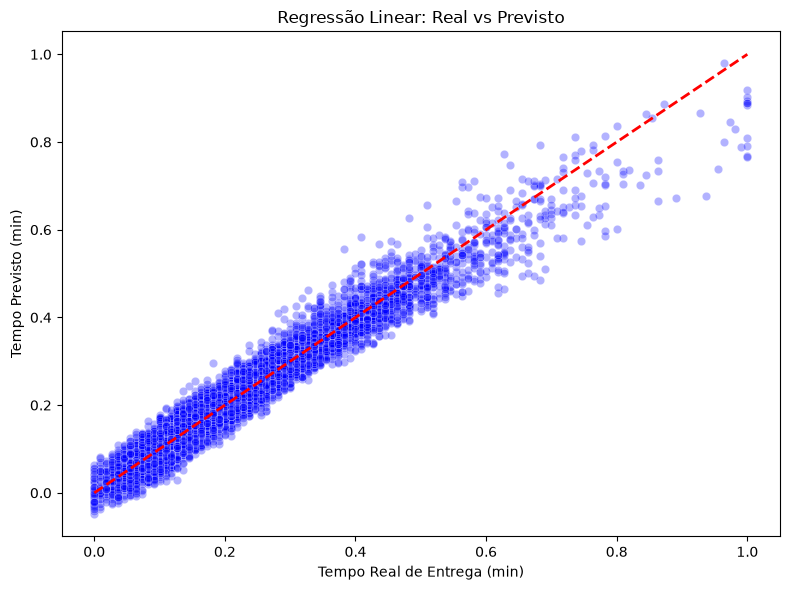

In [33]:
import sys
import os
sys.path.append(os.path.abspath('..'))

from src.visualization import plot_regression_results

plot_regression_results(y_test, y_pred)